# Programming Assignment 2: Classification Task and Performance Evaluation

**Image dataset:** Animal_Classification (https://www.kaggle.com/datasets/ayushv322/animal-classification)

**Classes:** Buffalo, Elephant, Rhino, Zebra  

**Assigned classifiers:** Naive Bayes, Neural Network, Random Forest

**GitHub Link:** https://github.com/mfshahriar/Data-Mining


## 1. Data Preparation


### Helpers (reused from PA1)




In [ ]:
from pathlib import Path

import numpy as np
from skimage import io, color, filters, exposure
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

DATA = Path.cwd() / "Animal_Classification"
CLASSES = ["Buffalo", "Elephant", "Rhino", "Zebra"]


def all_images(animal):
    return sorted((DATA / animal).glob("*.jpg"))

def load_gray(path):
    img = io.imread(path)
    return color.rgb2gray(img)

def angle(dx, dy):
    return np.mod(np.arctan2(dy, dx), np.pi)

def edge_hist(gray):
    angles = angle(filters.sobel_h(gray), filters.sobel_v(gray))
    hist, _ = exposure.histogram(angles, nbins=36)
    return hist

### 1(a),(b) 36-D edge histograms

Using all images.


In [ ]:
CACHE = Path.cwd() / "pa2_edge_hist.npz"
# building histograms for 4000 images is slow, hence saving them once

if CACHE.exists():
    data = np.load(CACHE, allow_pickle=True)
    X = data["X"]
    y = data["y"]
    paths = data["paths"]
    #print("Cached Features ->", CACHE.name)
else:
    histograms, labels, paths = [], [], []
    for animal in CLASSES:
        for path in all_images(animal):
            histograms.append(edge_hist(load_gray(path)))
            labels.append(animal)
            paths.append(str(path))
        print("Finished", animal, ":", len(all_images(animal)), "images")
    X = np.array(histograms)
    y = np.array(labels)
    paths = np.array(paths)
    np.savez(CACHE, X=X, y=y, paths=paths)
    print("Saved features to", CACHE.name)

print("Number of images:", X.shape[0])
print("Number of classes:", len(CLASSES))
print("Images per class:")
for animal in CLASSES:
    print(" ", animal, ":", (y == animal).sum())
print("Feature dimensionality:", X.shape[1])


Cached Features -> pa2_edge_hist.npz
Number of images: 4000
Number of classes: 4
Images per class:
  Buffalo : 1000
  Elephant : 1000
  Rhino : 1000
  Zebra : 1000
Feature dimensionality: 36


### 1(c) Stratified 80/20 train–test split


In [78]:
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X, y, paths, test_size=0.2, random_state=42, stratify=y # setting stratify=y to keep around the same class mix in train and test
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])
print("Train counts:", {animal: (y_train == animal).sum() for animal in CLASSES})
print("Test counts:", {animal: (y_test == animal).sum() for animal in CLASSES})


Train size: 3200
Test size: 800
Train counts: {'Buffalo': 800, 'Elephant': 800, 'Rhino': 800, 'Zebra': 800}
Test counts: {'Buffalo': 200, 'Elephant': 200, 'Rhino': 200, 'Zebra': 200}


### 1(d),(e) Standardization 

In [80]:
scaler = StandardScaler()

# learning mean/std from training data only
X_train_std = scaler.fit_transform(X_train)

X_test_std = scaler.transform(X_test)

print("Train shape:", X_train_std.shape)
print("Test shape:", X_test_std.shape)


Train shape: (3200, 36)
Test shape: (800, 36)


Computing standardization using the entire dataset means computing the mean and standard deviation of test data as well. This means we are effectively leaking testing data distribution information into data preprocessing. Hence, the eventual trained model will have insight regarding test data, potentially getting better accuracy, which may not reflect real life. 


## 2. Performance Comparison

Assigned methods: **Naive Bayes**, **Neural Network**, **Random Forest**.


### 2(a) Stratified 5-fold cross-validation on the training set


In [81]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

models = {
    "Naive Bayes": GaussianNB(),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(10, 10, 10), random_state=42),
    "Random Forest": RandomForestClassifier(random_state=32),
}


#### Stratified 5-fold CV on the training set


In [82]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=45)

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train_std, y_train, cv=cv, scoring="accuracy")
    rows.append({
        "Classifier": name,
        "Mean Val Acc": round(scores.mean(), 4),
        "Std Dev": round(scores.std(), 4),
    })

pd.DataFrame(rows)


,Classifier,Mean Val Acc,Std Dev
0,Naive Bayes,0.2888,0.0074
1,Neural Network,0.4316,0.0133
2,Random Forest,0.4559,0.0056


### 2(b) Which classifier to select based only on CV?

**Random Forest** has the highest mean validation accuracy (0.4559) and lowest std (0.0056). That is, it is the most accurate and potentially most stable model among all three. Hence I would choose Random forest. 


### 2(c) Training on full training set


#### Train each model and score the test set


In [ ]:
test_preds = {}
rows = []

for name, model in models.items():
    model.fit(X_train_std, y_train)
    pred = model.predict(X_test_std)

    test_preds[name] = pred
    rows.append({
        "Classifier": name,
        "Test Acc": round(accuracy_score(y_test, pred), 4),
        "Macro F1": round(f1_score(y_test, pred, average="macro"), 4),
    })

pd.DataFrame(rows)

,Classifier,Test Acc,Macro F1
0,Naive Bayes,0.2900,0.2100
1,Neural Network,0.4525,0.4500
2,Random Forest,0.4763,0.4772


#### Confusion matrices


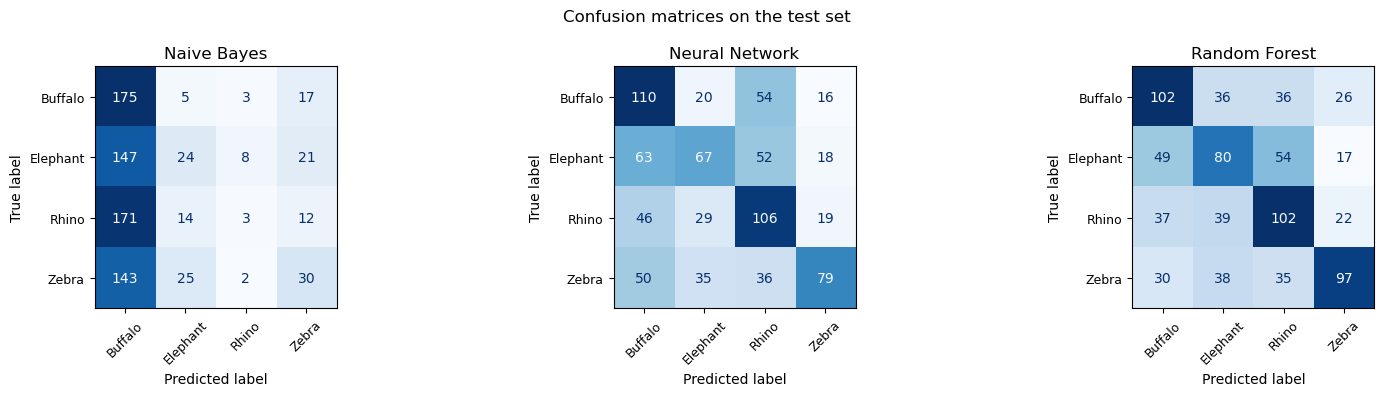

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("Confusion matrices on the test set")

for ax, (name, pred) in zip(axes, test_preds.items()):
    cm = confusion_matrix(y_test, pred, labels=CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)

plt.tight_layout()
plt.show()

### 2(d) Most frequently confused class pair

Across the confusion matrices, it seems Buffalo and Rhino are the most frequently confused. Perhaps because the body shape is big and similar, they overpower buffolo and rino horn's features, that are not strong enough for the models with such low amount of training instances to learn and distinguish. As we are working with edge histograms, the body outline can look very similar. We may need a more effective feature that can better discriminate.

### 2(e) Two misclassified images: Classifier -> Random Forest, Class Pair -> (Buffalo, Rino)


Image: Buffalo_314.jpg
  True class:      Buffalo
  Predicted class: Rhino

Image: Rhino_404.jpg
  True class:      Rhino
  Predicted class: Buffalo



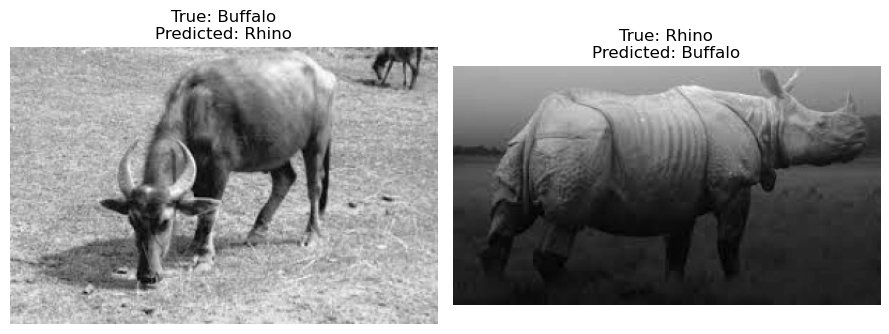

In [ ]:
rf_pred = test_preds["Random Forest"]

mistakes = []
for true_label, pred_label, path in zip(y_test, rf_pred, paths_test): # finding every test image where RF mixed up Buffalo and Rhino
    buffalo_rhino_error = (
        (true_label == "Buffalo" and pred_label == "Rhino")
        or (true_label == "Rhino" and pred_label == "Buffalo")
    )
    if buffalo_rhino_error:
        mistakes.append((path, true_label, pred_label))

shown = []
for want_true, want_pred in [("Buffalo", "Rhino"), ("Rhino", "Buffalo")]:
    for path, true_label, pred_label in mistakes:
        if true_label == want_true and pred_label == want_pred:
            shown.append((path, true_label, pred_label)) # keeping one mistake example for each
            break  

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (path, true_label, pred_label) in zip(axes, shown):
    ax.imshow(load_gray(path), cmap="gray")
    ax.set_title("True: " + true_label + "\nPredicted: " + pred_label)
    ax.axis("off")
    print("Image:", Path(path).name)
    print("  True class:     ", true_label)
    print("  Predicted class:", pred_label)
    print()

plt.tight_layout()
plt.show()


In both of the images, the body structure is similar, the model can also mistake rino ears with buffolo horns. At the end of the day, the 36 bin histogram can produce very similar edge structure for animals with similar bulky body.

## 3. Model Selection and Model Complexity

Two classes: **Buffalo** and **Rhino** (hardest pair from Section 2).


### 3(a) SVM with LinearSVC

In [ ]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.svm import LinearSVC

pair = ["Buffalo", "Rhino"]

# build smaller train/test sets by keeping only these two labels
X2_train, y2_train = [], []
for features, label in zip(X_train_std, y_train):
    if label in pair:
        X2_train.append(features)
        y2_train.append(label)

X2_test, y2_test = [], []
for features, label in zip(X_test_std, y_test):
    if label in pair:
        X2_test.append(features)
        y2_test.append(label)

X2_train, y2_train, X2_test, y2_test = map(np.array, (X2_train, y2_train, X2_test, y2_test))
Cs = [0.01, 0.1, 1, 10, 100, 1000]
kf = KFold(n_splits=5, shuffle=True, random_state=42)              # standard CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # stratified CV


In [ ]:
def cv_errors(cv): # for computing train-val error 
    train_errs = []
    val_errs = []
    for C in Cs:
        model = LinearSVC(C=C)
        results = cross_validate(
            model, X2_train, y2_train,
            cv=cv,    
            scoring="accuracy",   
            return_train_score=True,
        )
        train_err = 1 - results["train_score"].mean() # Error = 1 - Accuracy
        val_err = 1 - results["test_score"].mean()
        train_errs.append(train_err)
        val_errs.append(val_err)
    return np.array(train_errs), np.array(val_errs)


#### Standard and stratified 5-fold CV


In [109]:
standard_train_err, standard_val_err = cv_errors(kf)
strat_train_err, strat_val_err = cv_errors(skf)

#print("Standard CV validation errors:", np.round(standard_val_err, 4))
#print("Stratified CV validation errors:", np.round(strat_val_err, 4))

cv_table = pd.DataFrame({
    "C": Cs,
    "Standard train err": np.round(standard_train_err, 4),
    "Standard val err": np.round(standard_val_err, 4),
    "Stratified train err": np.round(strat_train_err, 4),
    "Stratified val err": np.round(strat_val_err, 4),
})
cv_table


,C,Standard train err,Standard val err,Stratified train err,Stratified val err
0,0.01,0.3341,0.3388,0.3355,0.3388
1,0.10,0.3305,0.3394,0.3314,0.3513
2,1.00,0.3261,0.3469,0.3281,0.3456
3,10.00,0.3253,0.3475,0.3278,0.3463
4,100.00,0.3248,0.3456,0.3278,0.3475
5,1000.00,0.3245,0.3456,0.3280,0.3475


#### Error curves


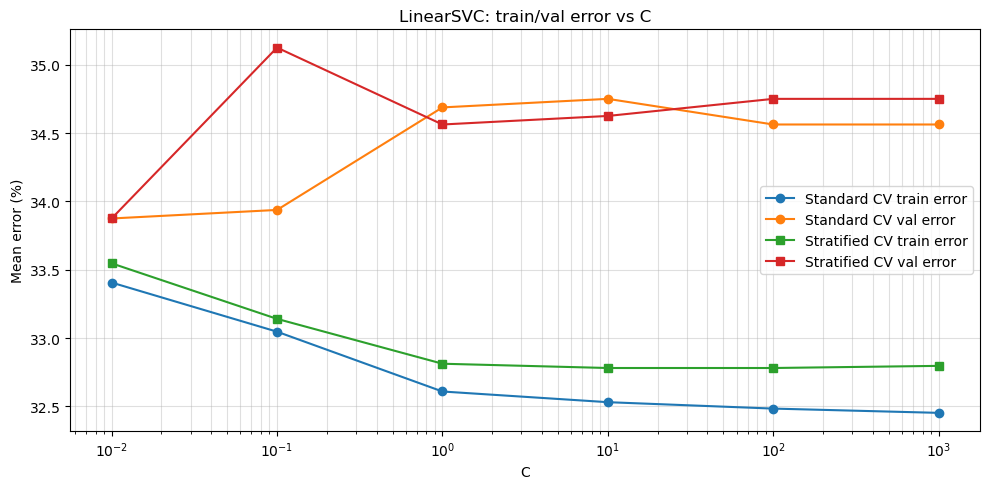

In [113]:
plt.figure(figsize=(10, 5))
plt.plot(Cs, standard_train_err * 100, marker="o", label="Standard CV train error")
plt.plot(Cs, standard_val_err * 100, marker="o", label="Standard CV val error")
plt.plot(Cs, strat_train_err * 100, marker="s", label="Stratified CV train error")
plt.plot(Cs, strat_val_err * 100, marker="s", label="Stratified CV val error")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Mean error (%)")
plt.title("LinearSVC: train/val error vs C")
plt.legend()
plt.grid(True, which="both", alpha=0.4)
plt.tight_layout()
plt.show()


### 3(b)


- Best C: standard CV -> C = 0.01; stratified CV -> C = 0.01 .
- Increasing C means less regularization ie., more complex models
- On average, training and validation error is around 32%-35%, which is quite high and signs of possible underfitting.
- Possible overfitting as C increases because as C increases, training error seems to go lower, but validating error is either stuck or even slightly increasing.
- In terms of results, they both look similar, although in the graph, we can see some jumping when dealing with validation error for both. Classes are balanced.

### 3(c)


In [ ]:
best_index = int(np.argmin(strat_val_err))
best_C = Cs[best_index]
print("Best C from stratified CV:", best_C)

model = LinearSVC(C=best_C)
model.fit(X2_train, y2_train)
pred = model.predict(X2_test)
test_error = 1 - accuracy_score(y2_test, pred)

print("Stratified CV mean validation error:", round(strat_val_err.min(), 4))
print("Held-out test error:", round(test_error, 4))

Best C from stratified CV: 0.01
Stratified CV mean validation error: 0.3388
Held-out test error: 0.345


Test error is close to the stratified CV validation error, highlighting reasonably consistent cross validation estimation.


## 4. Final Analysis: What Did You Learn?

From this analysis, with this particular data, and particular feature (36 bin histogram), Random Forest seems to perform best. Although, these testing accuracies are still quite low. A flip of a coin is better than all of the classifiers.

On stratified 5-fold CV it had the best mean validation accuracy as well as on the held-out test set. From the Confusion matrices, it seems Buffalo and Rhino are the hardest to distinguish, possibly because they have similar big bulky body, which are difficult to distinguish with feachers like 36-bin edge histograms. I don't think it is a very useful feature, when accuracy is close to a coin flip. So, an immediate improvement could be using more rich features that can capture texture, color etc. 
